# 01 · Cadrage et analyse exploratoire
**Projet final S7MOI1 — Prévoir la consommation électrique du lendemain**

---
## Axe 1 · Note de cadrage

| Élément | Réponse |
|---|---|
| **Contexte** | Un fournisseur d'électricité fictif achète à l'avance l'énergie qu'il revend à ses clients. Données : un foyer situé à Sceaux (France), mesures à la minute de décembre 2006 à novembre 2010. Utilisateur final : le responsable de l'approvisionnement. |
| **Problème** | Le fournisseur n'a pas de prévision fiable de la consommation du lendemain : s'il achète trop, le surplus est revendu moins cher ; s'il n'achète pas assez, il rachète en urgence à un prix plus élevé. |
| **Décision éclairée** | Chaque jour avant 10 h, fixer la quantité d'énergie à acheter pour le lendemain (consommation totale en kWh). Horizon : J+1. |
| **Situation actuelle** | Pas de modèle : on suppose « demain = aujourd'hui ». C'est notre référence. |
| **Critère de succès** | Réduire d'au moins 20 % l'erreur moyenne (MAE) par rapport à cette référence, sur des données jamais vues. |
| **Contraintes** | Seules les données connues à la fin du jour J-1 sont utilisables ; découpage chronologique ; un seul foyer dans les données. |

## Axe 2 · Type de problème
- **Cible** : `Consommation_kWh` du jour J = somme sur 24 h de `Global_active_power / 60` (kW → kWh par minute). Valeur continue, connue pour tout l'historique.
- **Type** : **prévision** (régression sur série temporelle) → split chronologique, variables de retard (lags), `TimeSeriesSplit`.
- **Pourquoi pas les autres ?** Une classification perdrait l'information chiffrée (la cible est continue). Un clustering ignorerait la cible que l'on connaît. Une régression « classique » avec un split aléatoire mélangerait passé et futur.


## 0 · Imports et configuration

In [ ]:
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42

# Chemins RELATIFS : le projet doit marcher sur n'importe quelle machine
DATA_RAW = Path("data/raw")
DATA_PROCESSED = Path("data/processed")
FIGURES = Path("reports/figures")

for dossier in [DATA_RAW, DATA_PROCESSED, FIGURES]:
    dossier.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.figsize"] = (12, 4)

## 1 · Données
**Source** : UCI Machine Learning Repository, *Individual Household Electric Power Consumption* (id 235) — https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption
**Date de consultation** : 18/10/2026 · **Licence** : à confirmer sur la page UCI et à citer dans le README.

La cellule ci-dessous télécharge les données automatiquement (reproductibilité). Si le téléchargement échoue (réseau, URL qui change), elle te demande d'importer le ZIP à la main.

In [ ]:
# L'URL de téléchargement est celle du bouton "Download" de la page UCI (à vérifier si elle change)
URL_UCI = "https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip"

fichier_txt = DATA_RAW / "household_power_consumption.txt"

if fichier_txt.exists():
    print("Fichier déjà présent :", fichier_txt)
else:
    zip_path = DATA_RAW / "household_power_consumption.zip"
    try:
        import urllib.request
        urllib.request.urlretrieve(URL_UCI, zip_path)
    except Exception as erreur:
        print("Téléchargement automatique impossible :", erreur)
        print("Importe le ZIP téléchargé depuis la page UCI :")
        try:
            from google.colab import files
        except ImportError:
            raise FileNotFoundError("Télécharge le ZIP sur la page UCI et place-le dans data/raw/")
        uploaded = files.upload()
        nom_zip = next(nom for nom in uploaded if nom.lower().endswith(".zip"))
        Path(nom_zip).replace(zip_path)

    with zipfile.ZipFile(zip_path, "r") as archive:
        archive.extractall(DATA_RAW)

    print("Fichier extrait :", fichier_txt, "-", round(fichier_txt.stat().st_size / 1_000_000, 1), "Mo")

Fichier extrait : data/raw/household_power_consumption.txt - 133.0 Mo


In [ ]:
# "?" = valeur manquante dans ce fichier ; encodage latin1 comme dans ta version
df = pd.read_csv(
    fichier_txt,
    sep=";",
    na_values="?",
    low_memory=False,
    encoding="latin1",
)

# Colonne date + heure (le format précis est plus rapide et plus sûr que dayfirst=True)
df["DateTime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S",
)

print("Dimensions du dataset :", df.shape)
print("Période :", df["DateTime"].min(), "->", df["DateTime"].max())
display(df.head())

Dimensions du dataset : (2075259, 10)
Période : 2006-12-16 17:24:00 -> 2010-11-26 21:02:00


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,DateTime
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0,2006-12-16 17:24:00
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0,2006-12-16 17:25:00
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0,2006-12-16 17:26:00
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0,2006-12-16 17:27:00
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0,2006-12-16 17:28:00


### Dictionnaire des variables

| Variable | Type | Unité | Signification |
|---|---|---|---|
| `Date`, `Time` | texte | jj/mm/aaaa, hh:mm:ss | Horodatage de la mesure (1 ligne = 1 minute) |
| `Global_active_power` | float | kW | Puissance active moyenne du foyer sur la minute → **sert à calculer notre cible** |
| `Global_reactive_power` | float | kW | Puissance réactive moyenne |
| `Voltage` | float | V | Tension moyenne |
| `Global_intensity` | float | A | Intensité moyenne |
| `Sub_metering_1` | float | Wh | Cuisine (lave-vaisselle, four, micro-ondes) |
| `Sub_metering_2` | float | Wh | Buanderie (lave-linge, sèche-linge, frigo, lumière) |
| `Sub_metering_3` | float | Wh | Chauffe-eau et climatisation |

## 2 · Qualité des données

In [ ]:
df.info()

print("\nValeurs manquantes par colonne :")
print(df.isna().sum())

print("\nLignes entièrement dupliquées :", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 10 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   Date                   object        
 1   Time                   object        
 2   Global_active_power    float64       
 3   Global_reactive_power  float64       
 4   Voltage                float64       
 5   Global_intensity       float64       
 6   Sub_metering_1         float64       
 7   Sub_metering_2         float64       
 8   Sub_metering_3         float64       
 9   DateTime               datetime64[ns]
dtypes: datetime64[ns](1), float64(7), object(2)
memory usage: 158.3+ MB

Valeurs manquantes par colonne :
Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3  

In [ ]:
colonnes_mesures = [
    "Global_active_power", "Global_reactive_power", "Voltage",
    "Global_intensity", "Sub_metering_1", "Sub_metering_2", "Sub_metering_3",
]

lignes_incompletes = df[colonnes_mesures].isna().any(axis=1).sum()
print("Lignes avec au moins une valeur manquante :", lignes_incompletes,
      "(", round(lignes_incompletes / len(df) * 100, 2), "% )")
print("Lignes où TOUTES les mesures sont manquantes :",
      df[colonnes_mesures].isna().all(axis=1).sum())

# Où sont ces manquants ? On les compte par jour.
df["Jour"] = df["DateTime"].dt.normalize()
manquantes = df[df["Global_active_power"].isna()]
manquantes_par_jour = manquantes.groupby("Jour").size()

print("\nNombre de jours concernés :", len(manquantes_par_jour))
print("Jours dont les 1440 minutes sont manquantes :", (manquantes_par_jour == 1440).sum())
display(manquantes_par_jour.sort_values(ascending=False).head(10))

Lignes avec au moins une valeur manquante : 25979 ( 1.25 % )
Lignes où TOUTES les mesures sont manquantes : 25979

Nombre de jours concernés : 82
Jours dont les 1440 minutes sont manquantes : 9


,0
Jour,
2007-04-29,1440
2009-06-14,1440
2010-01-13,1440
2010-08-21,1440
2010-09-27,1440
2010-09-26,1440
2010-08-20,1440
2010-08-18,1440
2010-08-19,1440


**Interprétation** : 25 979 lignes (1,25 %) ont des valeurs manquantes, et dans chacune d'elles toutes les mesures manquent en même temps : cela ressemble à une coupure du capteur plutôt qu'à des erreurs isolées. Ces trous sont regroupés par journées : ils touchent 82 journées, dont 9 sont entièrement vides.

**Décision de traitement** : on ne garde que les journées complètes (1 440 minutes), car une somme sur une journée incomplète sous-estimerait la consommation. On ne remplace pas les trous par une moyenne : on ne veut pas inventer des consommations.

In [ ]:
# Pour chaque jour : combien de mesures, combien de mesures valides ?
bilan_journalier = df.groupby("Jour").agg(
    nombre_lignes=("Global_active_power", "size"),
    mesures_disponibles=("Global_active_power", "count"),
)

jours_complets = bilan_journalier[bilan_journalier["mesures_disponibles"] == 1440].index

print("Nombre de journées au total :", len(bilan_journalier))
print("Journées complètes (1440 mesures valides) :", len(jours_complets))
print("Journées écartées :", len(bilan_journalier) - len(jours_complets))

df_complet = df[df["Jour"].isin(jours_complets)].copy()
print("Lignes conservées :", len(df_complet))

Nombre de journées au total : 1442
Journées complètes (1440 mesures valides) : 1358
Journées écartées : 84
Lignes conservées : 1955520


## 3 · Construction de la cible : consommation journalière en kWh

In [ ]:
# Une mesure en kW sur 1 minute = kW / 60 en kWh. On additionne sur la journée.
df_complet["energie_kWh"] = df_complet["Global_active_power"] / 60

conso = df_complet.groupby("Jour")["energie_kWh"].sum().reset_index()
conso.columns = ["Date", "Consommation_kWh"]
conso = conso.sort_values("Date").reset_index(drop=True)

print("Nombre de journées :", len(conso))
display(conso.head(10))
display(conso["Consommation_kWh"].describe().round(2))

Nombre de journées : 1358


,Date,Consommation_kWh
0,2006-12-17,56.507667
1,2006-12-18,36.730433
2,2006-12-19,27.769900
3,2006-12-20,37.095800
4,2006-12-22,39.022300
5,2006-12-23,79.556433
6,2006-12-24,42.500200
7,2006-12-25,45.718667
8,2006-12-26,65.568500
9,2006-12-27,25.479333


,Consommation_kWh
count,1358.00
mean,25.98
std,9.93
min,4.17
25%,19.43
50%,25.58
75%,31.45
max,79.56


In [ ]:
# Les jours écartés créent des "trous" dans le calendrier : combien ?
ecarts = conso["Date"].diff().dt.days

print("Écarts de 1 jour (consécutifs) :", (ecarts == 1).sum())
print("Écarts supérieurs à 1 jour (trous) :", (ecarts > 1).sum())

# On sauvegarde la table propre pour les notebooks suivants
conso.to_csv(DATA_PROCESSED / "conso_journaliere.csv", index=False)
print("\nSauvegardé :", DATA_PROCESSED / "conso_journaliere.csv")

Écarts de 1 jour (consécutifs) : 1290
Écarts supérieurs à 1 jour (trous) : 67

Sauvegardé : data/processed/conso_journaliere.csv


**Conséquence pour la suite** : à cause des trous, le « jour précédent » ne se trouve pas toujours une ligne plus haut. Dans le notebook 02, les retards seront donc construits **par date** (J-1, J-7) sur un calendrier complet, jamais par simple décalage de lignes.

## 4 · Analyse exploratoire

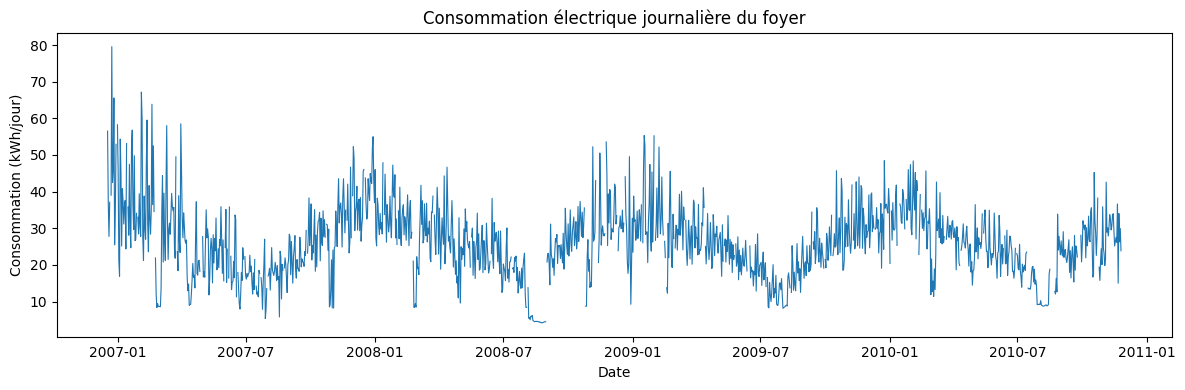

In [ ]:
conso_eda = conso.copy()

# Calendrier complet : les jours manquants apparaissent comme des trous dans la courbe
calendrier = pd.date_range(conso_eda["Date"].min(), conso_eda["Date"].max(), freq="D")
serie = conso_eda.set_index("Date")["Consommation_kWh"].reindex(calendrier)

plt.figure()
plt.plot(serie.index, serie.values, linewidth=0.8)
plt.title("Consommation électrique journalière du foyer")
plt.xlabel("Date")
plt.ylabel("Consommation (kWh/jour)")
plt.tight_layout()
plt.savefig(FIGURES / "01_serie_journaliere.png", dpi=150, bbox_inches="tight")
plt.show()

**Interprétation** : la consommation est nettement saisonnière : élevée en hiver (chauffage, éclairage), minimale en été, avec un creux très marqué en août 2008 (probablement une absence du foyer). Le niveau change donc selon la période, ce qui justifie la variable `mois`.

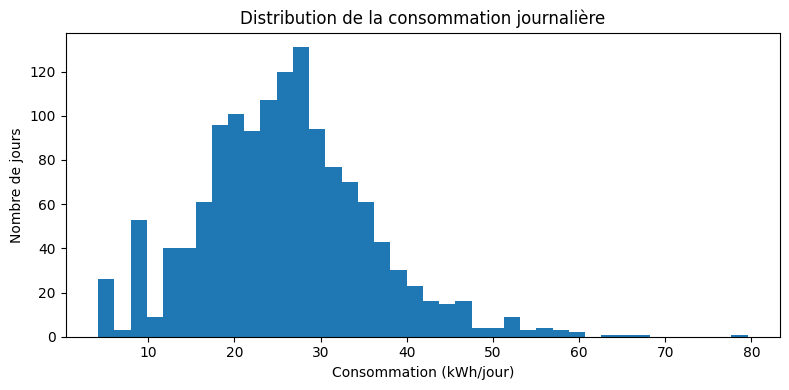

Asymétrie (skewness) : 0.55


In [ ]:
plt.figure(figsize=(8, 4))
plt.hist(conso_eda["Consommation_kWh"], bins=40)
plt.title("Distribution de la consommation journalière")
plt.xlabel("Consommation (kWh/jour)")
plt.ylabel("Nombre de jours")
plt.tight_layout()
plt.savefig(FIGURES / "02_distribution_cible.png", dpi=150, bbox_inches="tight")
plt.show()

print("Asymétrie (skewness) :", round(conso_eda["Consommation_kWh"].skew(), 2))

**Interprétation** : la distribution est peu asymétrique (skewness de 0,55), légèrement étalée vers les fortes valeurs. Les journées les plus faibles (4,2 à 4,5 kWh) sont toutes en août 2008 et correspondent probablement à une absence du foyer ; les plus fortes (jusqu'à 79,6 kWh) sont en hiver 2006-2007.

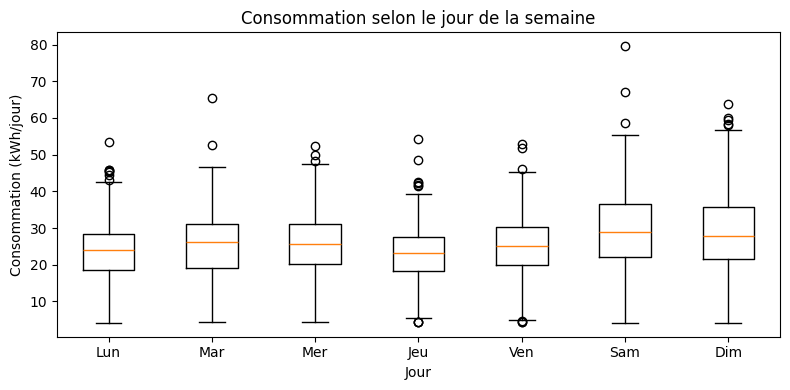

In [ ]:
conso_eda["jour_semaine"] = conso_eda["Date"].dt.dayofweek
conso_eda["mois"] = conso_eda["Date"].dt.month

noms_jours = ["Lun", "Mar", "Mer", "Jeu", "Ven", "Sam", "Dim"]
groupes = []
for jour in range(7):
    groupes.append(conso_eda.loc[conso_eda["jour_semaine"] == jour, "Consommation_kWh"])

plt.figure(figsize=(8, 4))
plt.boxplot(groupes)
plt.xticks(range(1, 8), noms_jours)
plt.title("Consommation selon le jour de la semaine")
plt.xlabel("Jour")
plt.ylabel("Consommation (kWh/jour)")
plt.tight_layout()
plt.savefig(FIGURES / "03_jour_semaine.png", dpi=150, bbox_inches="tight")
plt.show()

**Interprétation** : le week-end consomme plus que la semaine : 28,8 kWh en moyenne contre 24,7 kWh (environ +17 %), le samedi étant le jour le plus élevé. L'effet est assez net pour justifier une variable `week_end`.

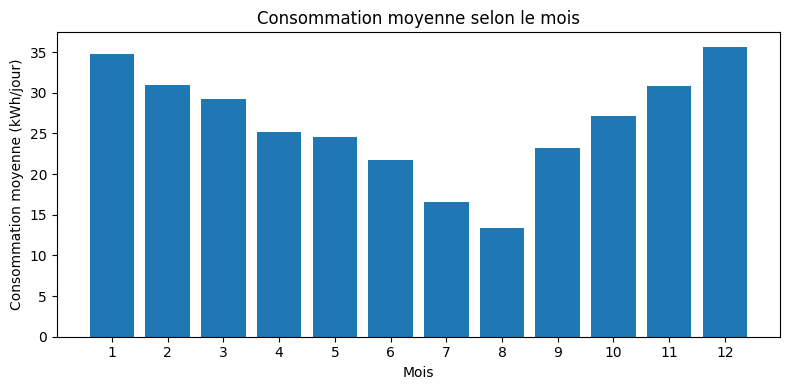

In [ ]:
moyenne_par_mois = conso_eda.groupby("mois")["Consommation_kWh"].mean()

plt.figure(figsize=(8, 4))
plt.bar(moyenne_par_mois.index, moyenne_par_mois.values)
plt.xticks(range(1, 13))
plt.title("Consommation moyenne selon le mois")
plt.xlabel("Mois")
plt.ylabel("Consommation moyenne (kWh/jour)")
plt.tight_layout()
plt.savefig(FIGURES / "04_mois.png", dpi=150, bbox_inches="tight")
plt.show()

**Interprétation** : les mois de décembre et janvier consomment le plus (environ 34,5 kWh/jour), et août le moins (environ 12,7 kWh/jour). C'est cohérent avec le chauffage et l'éclairage en hiver.

In [ ]:
# La consommation d'aujourd'hui ressemble-t-elle à celle d'hier ? De la semaine dernière ?
for decalage in [1, 2, 7, 14]:
    correlation = serie.corr(serie.shift(decalage))
    print("Corrélation avec la consommation à J-" + str(decalage), ":", round(correlation, 3))

Corrélation avec la consommation à J-1 : 0.616
Corrélation avec la consommation à J-2 : 0.495
Corrélation avec la consommation à J-7 : 0.547
Corrélation avec la consommation à J-14 : 0.468


**Interprétation** : la consommation d'un jour est surtout corrélée à celle de la veille (0,62), puis de J-7 (0,55), de J-2 (0,50) et de J-14 (0,47). Cela justifie le choix de `Consommation_veille` (J-1) et `Consommation_semaine_precedente` (J-7) comme variables.

In [ ]:
print("10 journées les plus faibles :")
display(conso_eda.nsmallest(10, "Consommation_kWh")[["Date", "Consommation_kWh"]])

print("10 journées les plus fortes :")
display(conso_eda.nlargest(10, "Consommation_kWh")[["Date", "Consommation_kWh"]])

10 journées les plus faibles :


,Date,Consommation_kWh
586,2008-08-25,4.171633
584,2008-08-23,4.244033
585,2008-08-24,4.245267
587,2008-08-26,4.292733
588,2008-08-27,4.301900
582,2008-08-21,4.354967
583,2008-08-22,4.452067
590,2008-08-29,4.459800
589,2008-08-28,4.470767
581,2008-08-20,4.474533


10 journées les plus fortes :


,Date,Consommation_kWh
5,2006-12-23,79.556433
44,2007-02-03,67.162033
8,2006-12-26,65.568500
59,2007-02-18,63.829367
45,2007-02-04,59.932333
52,2007-02-11,59.520467
98,2007-03-31,58.491833
12,2006-12-31,58.236600
79,2007-03-11,58.010600
32,2007-01-21,56.787700


## 5 · Audit de fuite de données et table finale pour la modélisation
Le modèle doit prédire la consommation d'un jour avec ce qui est connu à la fin du jour précédent. On **exclut** donc `Global_reactive_power`, `Voltage`, `Global_intensity` et les trois `Sub_metering` du jour à prédire : ils sont mesurés en même temps que la cible (`Global_intensity` est quasi proportionnelle à la puissance qui sert à la calculer).

Variables construites : la consommation de la veille (J-1) et celle du même jour la semaine précédente (J-7), calculées **par date**, plus le jour de la semaine, le mois et un indicateur de week-end. Une ligne dont le jour de référence est absent est retirée.

In [ ]:
# Table finale pour 02_modelisation : une ligne = un jour complet, retards construits PAR DATE
calendrier = pd.date_range(conso["Date"].min(), conso["Date"].max(), freq="D")
serie_complete = conso.set_index("Date")["Consommation_kWh"].reindex(calendrier)

features = pd.DataFrame({"Consommation_kWh": serie_complete})
features["jour_semaine"] = features.index.dayofweek
features["mois"] = features.index.month
features["est_we"] = (features["jour_semaine"] >= 5).astype(int)
features["conso_J_minus_1"] = serie_complete.shift(1)
features["conso_J_minus_7"] = serie_complete.shift(7)

# On retire les lignes sans cible ou sans retard (jours écartés)
features = features.dropna().rename_axis("Date").reset_index()

features.to_csv(DATA_PROCESSED / "features_conso.csv", index=False)
print("Lignes dans features_conso.csv :", len(features))
display(features.head())